<a href="https://colab.research.google.com/github/jiiaojie/career-ops/blob/main/windspeed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
# 固定随机种子，让每次运行得到相同的模拟数据
np.random.seed(42)

n = 1000

# 每小时一条数据
timestamps = pd.date_range(
    start="2025-01-01",
    periods=n,
    freq="h"
)

# 模拟参考风场风速，单位 m/s
reference_speed = (
    7
    + 2.5 * np.sin(np.arange(n) * 2 * np.pi / 168)
    + np.random.normal(0, 1.8, n)
)

# 风速不能小于 0
reference_speed = np.clip(reference_speed, 0, None)

# 模拟目标风场风速：
# 两个风场相关，但不完全相同
target_speed = (
    0.85 * reference_speed
    + 1.0
    + np.random.normal(0, 0.8, n)
)

target_speed = np.clip(target_speed, 0, None)

# 创建数据表
df = pd.DataFrame({
    "timestamp": timestamps,
    "reference_wind_speed": reference_speed,
    "target_wind_speed": target_speed
})

# 模拟一次数据缺失事件：第 800 到 849 小时
outage_start = 800
outage_end = 850

df.loc[
    outage_start:outage_end - 1,
    "target_wind_speed"
] = np.nan

print(df.head())
print("\nMissing target wind speeds:",
      df["target_wind_speed"].isna().sum())

            timestamp  reference_wind_speed  target_wind_speed
0 2025-01-01 00:00:00              7.894085           8.829457
1 2025-01-01 01:00:00              6.844602           7.557619
2 2025-01-01 02:00:00              8.352665           8.147469
3 2025-01-01 03:00:00             10.021365           9.000611
4 2025-01-01 04:00:00              6.951130           7.467039

Missing target wind speeds: 50


In [3]:
# 查看数据类型、非空数量等
print(df.info())

# 检查缺失值
print("\nMissing values:")
print(df.isna().sum())

# 查看基本统计信息
print("\nSummary:")
print(df[[
    "reference_wind_speed",
    "target_wind_speed"
]].describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   timestamp             1000 non-null   datetime64[ns]
 1   reference_wind_speed  1000 non-null   float64       
 2   target_wind_speed     950 non-null    float64       
dtypes: datetime64[ns](1), float64(2)
memory usage: 23.6 KB
None

Missing values:
timestamp                0
reference_wind_speed     0
target_wind_speed       50
dtype: int64

Summary:
       reference_wind_speed  target_wind_speed
count           1000.000000         950.000000
mean               7.038136           7.093182
std                2.504113           2.245965
min                0.080007           0.892567
25%                5.251768           5.454980
50%                7.001806           7.126664
75%                8.865645           8.726209
max               16.433168          16.367

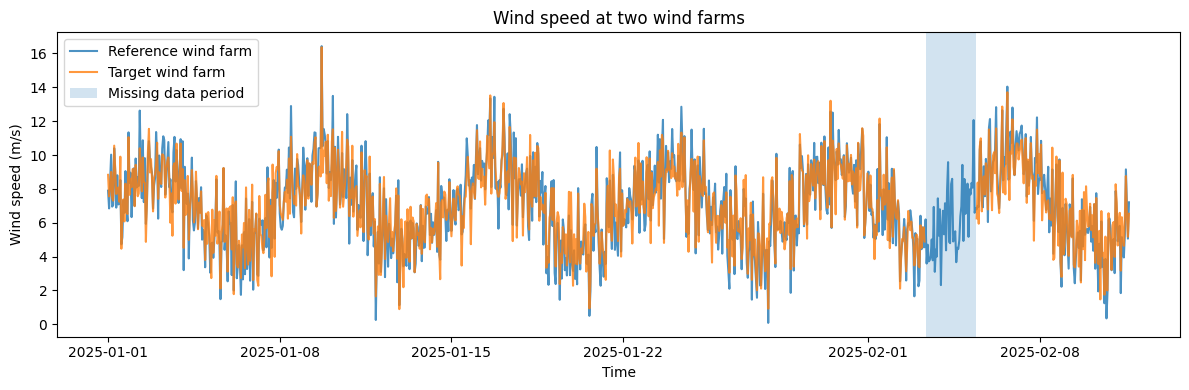

In [4]:
plt.figure(figsize=(12, 4))

plt.plot(
    df["timestamp"],
    df["reference_wind_speed"],
    label="Reference wind farm",
    alpha=0.8
)

plt.plot(
    df["timestamp"],
    df["target_wind_speed"],
    label="Target wind farm",
    alpha=0.8
)

plt.axvspan(
    df.loc[outage_start, "timestamp"],
    df.loc[outage_end - 1, "timestamp"],
    alpha=0.2,
    label="Missing data period"
)

plt.xlabel("Time")
plt.ylabel("Wind speed (m/s)")
plt.title("Wind speed at two wind farms")
plt.legend()
plt.tight_layout()
plt.show()

check if the two wind farm wind speed correlates with each other.

Correlation: 0.935


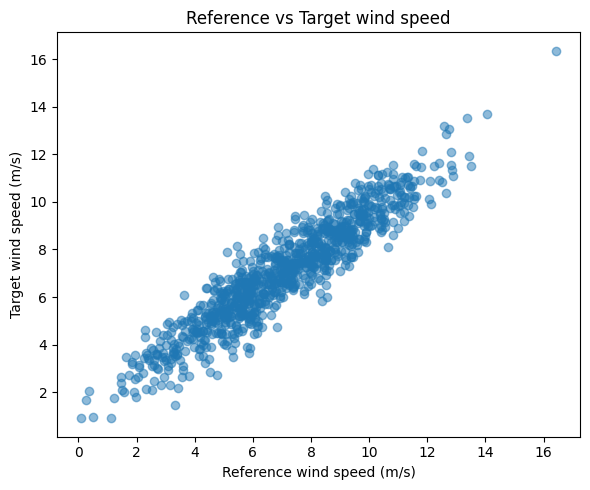

In [5]:
observed = df.dropna(
    subset=["target_wind_speed"]
)

correlation = observed[
    ["reference_wind_speed", "target_wind_speed"]
].corr().iloc[0, 1]

print(f"Correlation: {correlation:.3f}")

plt.figure(figsize=(6, 5))

plt.scatter(
    observed["reference_wind_speed"],
    observed["target_wind_speed"],
    alpha=0.5
)

plt.xlabel("Reference wind speed (m/s)")
plt.ylabel("Target wind speed (m/s)")
plt.title("Reference vs Target wind speed")
plt.tight_layout()
plt.show()

In [6]:
# 用前 700 小时训练，用第 700–799 小时验证
train_df = df.iloc[:700].dropna(
    subset=["target_wind_speed"]
)

validation_df = df.iloc[700:800].dropna(
    subset=["target_wind_speed"]
)

X_train = train_df[["reference_wind_speed"]]
y_train = train_df["target_wind_speed"]

X_val = validation_df[["reference_wind_speed"]]
y_val = validation_df["target_wind_speed"]

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))

Training rows: 700
Validation rows: 100


In [7]:
# 模型 1：线性回归
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# 模型 2：随机森林回归
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42
)

rf_model.fit(X_train, y_train)

# 在验证集上预测
pred_linear = linear_model.predict(X_val)
pred_rf = rf_model.predict(X_val)

# 风速不应为负
pred_linear = np.clip(pred_linear, 0, None)
pred_rf = np.clip(pred_rf, 0, None)

# 计算误差
results = []

for name, prediction in [
    ("Linear Regression", pred_linear),
    ("Random Forest", pred_rf)
]:
    mae = mean_absolute_error(y_val, prediction)
    rmse = np.sqrt(mean_squared_error(y_val, prediction))

    results.append({
        "Model": name,
        "MAE (m/s)": mae,
        "RMSE (m/s)": rmse
    })

results_df = pd.DataFrame(results)

print(results_df)

               Model  MAE (m/s)  RMSE (m/s)
0  Linear Regression   0.605733    0.767024
1      Random Forest   0.640173    0.796982


MAE RMSE lower the better, but still need to check the validation in the graph

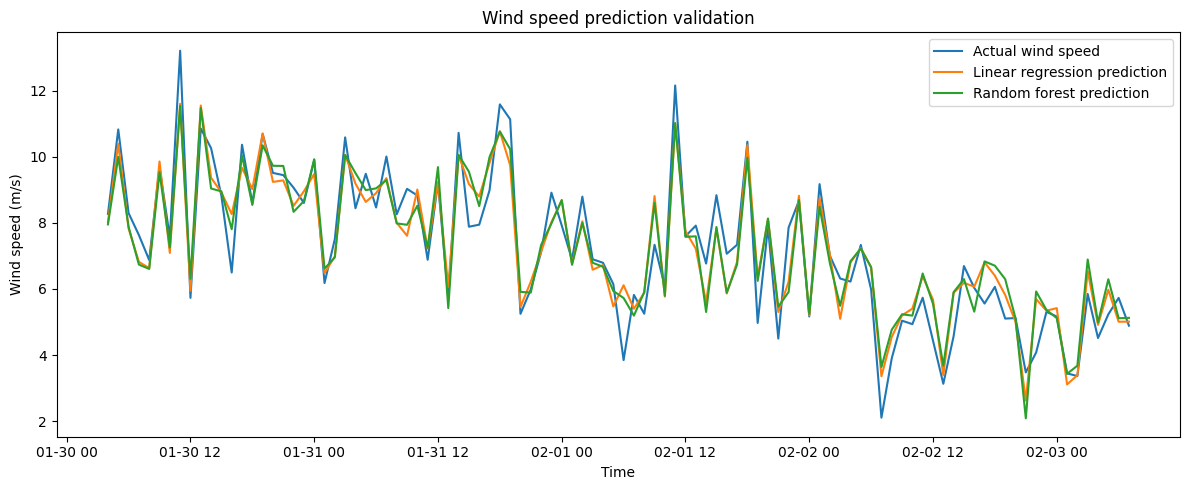

In [8]:
plt.figure(figsize=(12, 5))

plt.plot(
    validation_df["timestamp"],
    y_val.to_numpy(),
    label="Actual wind speed"
)

plt.plot(
    validation_df["timestamp"],
    pred_linear,
    label="Linear regression prediction"
)

plt.plot(
    validation_df["timestamp"],
    pred_rf,
    label="Random forest prediction"
)

plt.xlabel("Time")
plt.ylabel("Wind speed (m/s)")
plt.title("Wind speed prediction validation")
plt.legend()
plt.tight_layout()
plt.show()

prediction of the missing wind speed

In [9]:
# 根据验证集 RMSE 选择模型类型
best_name = results_df.loc[
    results_df["RMSE (m/s)"].idxmin(),
    "Model"
]

print("Selected model:", best_name)

# 用所有已知的目标风速重新训练
known_df = df.dropna(
    subset=["target_wind_speed"]
)

X_known = known_df[["reference_wind_speed"]]
y_known = known_df["target_wind_speed"]

if best_name == "Linear Regression":
    final_model = LinearRegression()
else:
    final_model = RandomForestRegressor(
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=5,
        random_state=42
    )

final_model.fit(X_known, y_known)

# 找到目标风速缺失的行
missing_mask = df["target_wind_speed"].isna()

# 预测缺失风速
df["predicted_wind_speed"] = np.nan

df.loc[missing_mask, "predicted_wind_speed"] = np.clip(
    final_model.predict(
        df.loc[missing_mask, ["reference_wind_speed"]]
    ),
    0,
    None
)

print(
    df.loc[
        missing_mask,
        ["timestamp", "reference_wind_speed",
         "predicted_wind_speed"]
    ].head(10)
)

Selected model: Linear Regression
              timestamp  reference_wind_speed  predicted_wind_speed
800 2025-02-03 08:00:00              6.195901              6.347559
801 2025-02-03 09:00:00              3.586839              4.173331
802 2025-02-03 10:00:00              4.700940              5.101753
803 2025-02-03 11:00:00              3.711488              4.277206
804 2025-02-03 12:00:00              3.780587              4.334788
805 2025-02-03 13:00:00              4.028676              4.541530
806 2025-02-03 14:00:00              5.010909              5.360061
807 2025-02-03 15:00:00              3.778544              4.333086
808 2025-02-03 16:00:00              6.933177              6.961957
809 2025-02-03 17:00:00              3.098301              3.766214


missing power calculation, this is just an example, need to correlate with the real power calculation formula.

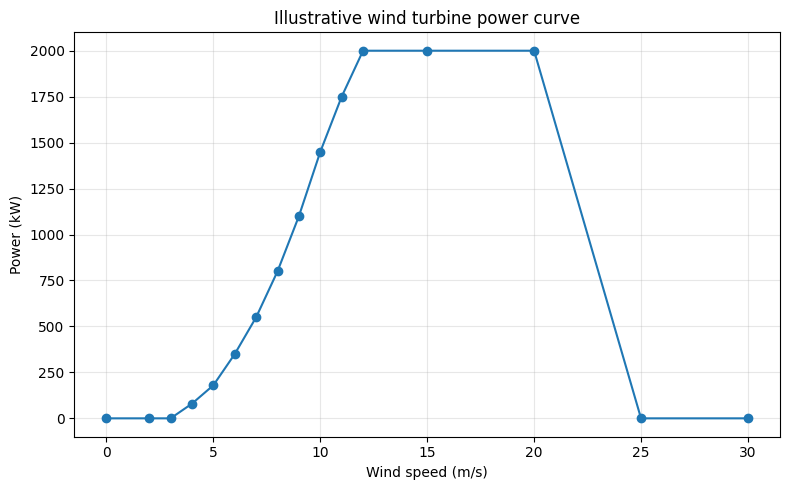

In [10]:
# 示例功率曲线
# 风速单位：m/s
# 功率单位：kW

power_curve = pd.DataFrame({
    "wind_speed": [0, 2, 3, 4, 5, 6, 7, 8,
                   9, 10, 11, 12, 15, 20, 25, 30],
    "power_kw":   [0, 0, 0, 80, 180, 350, 550, 800,
                   1100, 1450, 1750, 2000, 2000, 2000, 0, 0]
})

plt.figure(figsize=(8, 5))

plt.plot(
    power_curve["wind_speed"],
    power_curve["power_kw"],
    marker="o"
)

plt.xlabel("Wind speed (m/s)")
plt.ylabel("Power (kW)")
plt.title("Illustrative wind turbine power curve")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
#missing energy calculation from power
def wind_speed_to_power(wind_speed):
    """
    将风速 (m/s) 转换为估计功率 (kW)。
    这里使用示例功率曲线，不代表真实风机规格。
    """
    return np.interp(
        wind_speed,
        power_curve["wind_speed"],
        power_curve["power_kw"]
    )


# 对缺失时段的预测风速计算功率
df["estimated_power_kw"] = np.nan

df.loc[missing_mask, "estimated_power_kw"] = (
    df.loc[missing_mask, "predicted_wind_speed"]
    .apply(wind_speed_to_power)
)

# 假设每条记录间隔 1 小时
interval_hours = 1.0

df["estimated_energy_kwh"] = (
    df["estimated_power_kw"] * interval_hours
)

estimated_energy_loss = df.loc[
    missing_mask,
    "estimated_energy_kwh"
].sum()

print(
    f"Estimated energy yield during missing period: "
    f"{estimated_energy_loss:,.0f} kWh"
)

Estimated energy yield during missing period: 22,412 kWh


In [13]:
# 导出包含原始数据、预测风速和能源估算的完整表格
df.to_csv(
    "wind_farm_prediction_results.csv",
    index=False
)

# 生成缺失时段的单独报告
loss_report = df.loc[
    missing_mask,
    [
        "timestamp",
        "reference_wind_speed",
        "predicted_wind_speed",
        "estimated_power_kw",
        "estimated_energy_kwh"
    ]
].copy()

loss_report.to_csv(
    "wind_farm_energy_loss_report.csv",
    index=False
)

print("Files exported successfully.")
print(loss_report.head())

Files exported successfully.
              timestamp  reference_wind_speed  predicted_wind_speed  \
800 2025-02-03 08:00:00              6.195901              6.347559   
801 2025-02-03 09:00:00              3.586839              4.173331   
802 2025-02-03 10:00:00              4.700940              5.101753   
803 2025-02-03 11:00:00              3.711488              4.277206   
804 2025-02-03 12:00:00              3.780587              4.334788   

     estimated_power_kw  estimated_energy_kwh  
800          419.511724            419.511724  
801           97.333087             97.333087  
802          197.297935            197.297935  
803          107.720575            107.720575  
804          113.478825            113.478825  
